# LLM index

In [1]:
import torch
import random
import colorsys
import matplotlib.pyplot as plt
from datetime import timedelta

from llm_index.data import load_data
from llm_index.compute import fit
from llm_index.distribution import cumulative_split_normal, inverse_cumulative_split_normal

### Data

In [2]:
data = load_data()

print(f"{len(data.models)} models, {len(data.benchmarks)} benchmarks, {len(data.milestones)} milestones, {len(data.get_normalized_results())} non-null results")

35 models, 8 benchmarks, 6 milestones, 305 non-null results


### Compute

In [3]:
output = fit(data)

print()
print(f"final loss : {output.loss:.7f}")

epoch 0 | loss = 0.1907633
epoch 5,000 | loss = 0.0069018
epoch 10,000 | loss = 0.0004514
epoch 15,000 | loss = 0.0004513
epoch 20,000 | loss = 0.0004512
epoch 25,000 | loss = 0.0004512
epoch 29,999 | loss = 0.0004512

final loss : 0.0004474


### Results

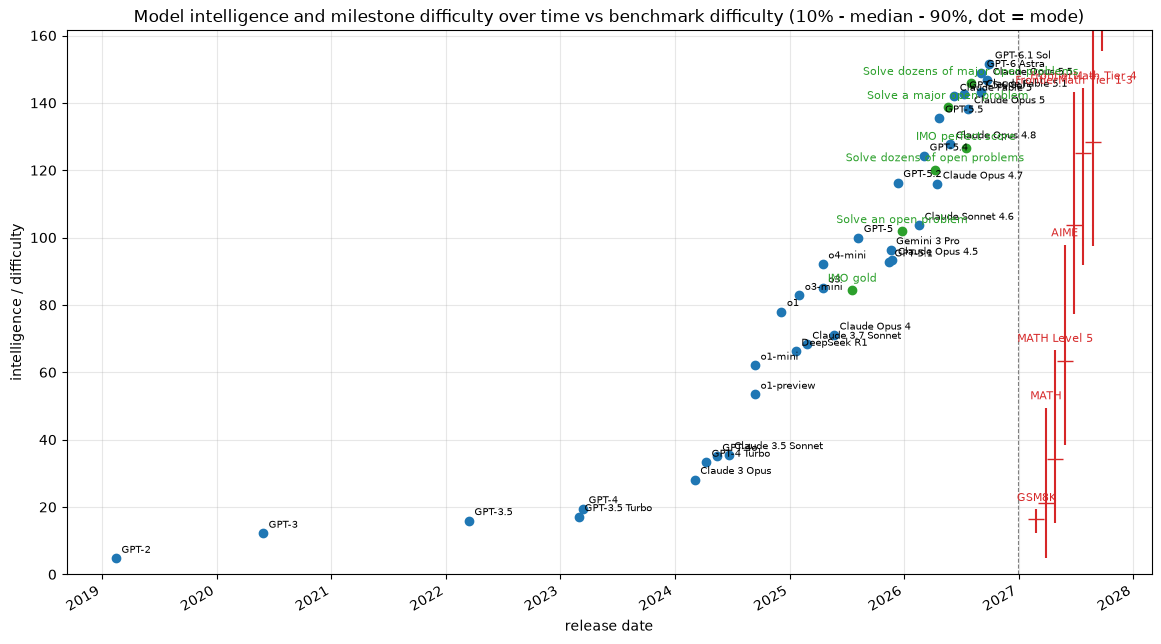

In [4]:
model_ids = list(data.models)
dates = [data.models[id].release_date for id in model_ids]
scores = [output.model_intelligences[id] for id in model_ids]

benchmark_ids = list(output.benchmark_difficulty_modes)
milestone_ids = list(output.milestone_difficulties)
benchmark_x0 = max(dates) + timedelta(days=150)

fig, ax = plt.subplots(figsize=(14, 8))

ax.plot(dates, scores, 'o', color='tab:blue')

for id, x, y in zip(model_ids, dates, scores):
	ax.annotate(data.models[id].name, (x, y), textcoords='offset points', xytext=(4, 4), fontsize=7)

quantiles = torch.tensor([0.1, 0.5, 0.9])
benchmark_medians = []

for i, id in enumerate(benchmark_ids):
	mode = torch.tensor(output.benchmark_difficulty_modes[id])
	low_std = torch.tensor(output.benchmark_difficulty_low_stds[id])
	high_std = torch.tensor(output.benchmark_difficulty_high_stds[id])
	low, median, high = inverse_cumulative_split_normal(quantiles, mode, low_std, high_std).tolist()
	benchmark_medians.append(median)
	x = benchmark_x0 + timedelta(days=30 * i)

	ax.vlines(x, low, high, color='tab:red', linewidth=1.5)
	ax.plot([x], [median], marker='_', markersize=12, color='tab:red')
	ax.annotate(data.benchmarks[id].name, (x, high), textcoords='offset points', xytext=(0, 6), fontsize=8, color='tab:red', ha='center')

for id in milestone_ids:
	difficulty = output.milestone_difficulties[id]
	x = data.milestones[id].date_first

	ax.plot([x], [difficulty], marker='o', markersize=6, color='tab:green')
	ax.annotate(data.milestones[id].name, (x, difficulty), textcoords='offset points', xytext=(0, 6), fontsize=8, color='tab:green', ha='center')

ax.axvline(max(dates) + timedelta(days=90), color='gray', linestyle='--', linewidth=0.8)

ax.set_xlabel('release date')
ax.set_ylabel('intelligence / difficulty')
ax.set_title('Model intelligence and milestone difficulty over time vs benchmark difficulty (10% - median - 90%, dot = mode)')
ax.set_ylim(0, max(scores) + 10)
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

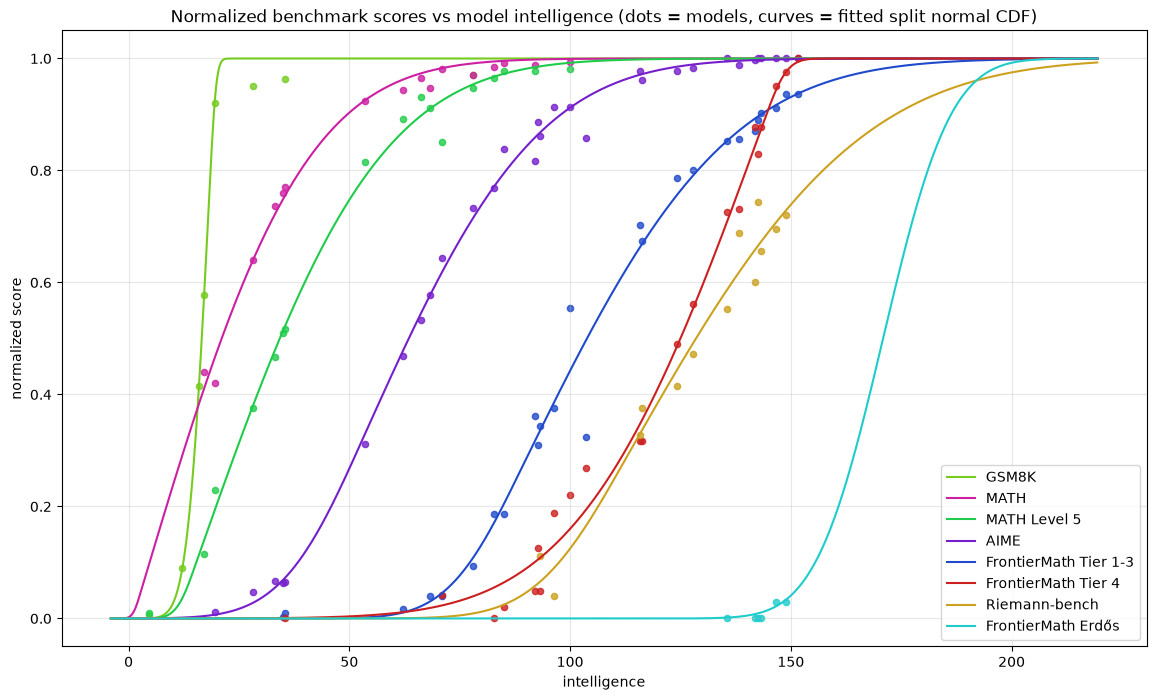

In [5]:
benchmark_ids = list(output.benchmark_difficulty_modes)
hues = [i / len(benchmark_ids) for i in range(len(benchmark_ids))]
random.shuffle(hues)

curve_bounds = []

for id in benchmark_ids:
	mode = torch.tensor(output.benchmark_difficulty_modes[id])
	low_std = torch.tensor(output.benchmark_difficulty_low_stds[id])
	high_std = torch.tensor(output.benchmark_difficulty_high_stds[id])
	curve_bounds += inverse_cumulative_split_normal(torch.tensor([0.01, 0.99]), mode, low_std, high_std).tolist()

intelligences = list(output.model_intelligences.values())
xs = torch.linspace(min(intelligences + curve_bounds) - 5, max(intelligences + curve_bounds) + 5, 1000)

fig, ax = plt.subplots(figsize=(14, 8))

for id, hue in zip(benchmark_ids, hues):
	color = colorsys.hsv_to_rgb(hue, 0.85, 0.8)
	mode = torch.tensor(output.benchmark_difficulty_modes[id])
	low_std = torch.tensor(output.benchmark_difficulty_low_stds[id])
	high_std = torch.tensor(output.benchmark_difficulty_high_stds[id])
	results = data.benchmarks[id].get_normalized_results()

	ax.plot(xs, cumulative_split_normal(xs, mode, low_std, high_std), color=color, linewidth=1.5, label=data.benchmarks[id].name)
	ax.scatter(
		[output.model_intelligences[model_id] for _, model_id, _ in results],
		[score for _, _, score in results],
		color=color, s=20, alpha=0.8,
	)

ax.set_xlabel('intelligence')
ax.set_ylabel('normalized score')
ax.set_title('Normalized benchmark scores vs model intelligence (dots = models, curves = fitted split normal CDF)')
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.3)
ax.legend()
plt.show()